# Image Classification using ResNet50

The objective is to use a pretrained ResNet50 model to recognise an elephant in an image.

**What is ResNet50 ?**
ResNet50 is a 50-layer convolutional neural network.

It uses a technique called residual learning.

In very deep networks, training can become difficult because information and gradients may not flow effectively through many layers.

- ResNet addresses this using shortcut connections, which allow information to bypass some layers.

A simplified residual block can be represented as:

$$
y=F(x)+x
$$

Where:
- $(x)$ = Original input.

- $(F(x))$ = Transformation performed by the network.

- $(y)$ = Combined output.

<img src='img/residual_learning.png' alt="Residual Learning" width=500>

The shortcut connection helps the network learn residual changes rather than requiring every layer to learn a completely new representation.

## Import the Libraries

In [1]:
import keras

from keras.applications.resnet50 import (
    ResNet50,
    preprocess_input,
    decode_predictions
)

import numpy as np
import matplotlib.pyplot as plt

Understanding the imports:
- `ResNet50`: Loads the pretrained model.

- `preprocess_input`: Prepares images in the format expected by ResNet50.

- `decode_predictions`: Converts prediction scores into readable class names.

- `numpy`: Handles image arrays.

- `matplotlib`: Displays images.

## Load the Pretrained Model

In [2]:
model = ResNet50(weights='imagenet')

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Explanation:

- weights='imagenet' loads the weights learned during ImageNet training.

- The model already understands many visual features.

- We do not need to train it from scratch.

## Load the Elephant Image

In [ ]:
# img_path = '../data/elephant.jpg'

img_path = 'data/elephant.jpg'

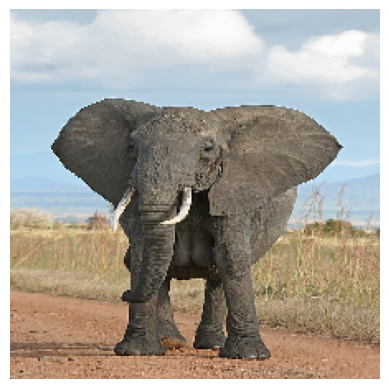

In [5]:
img = keras.utils.load_img(
    img_path,
    target_size=(224, 224)
)

plt.imshow(img)
plt.axis('off')
plt.show()

**Why resize to 224 × 224?**

ResNet50 expects an image with the spatial dimensions `224 × 224` when using its standard ImageNet configuration.

## Convert the Image into an Array

In [6]:
x = keras.utils.img_to_array(img)

x = np.expand_dims(x, axis=0)

x = preprocess_input(x)

Understanding each operation.

1. Convert image to array:

```bash
x = keras.utils.img_to_array(img)
```

Converts the image into numerical pixel values.

- Its shape becomes:

$$
(224,224,3)
$$

Add batch dimension:
```bash
x = np.expand_dims(x, axis=0)
```
Neural networks generally expect batches of images.

The new shape becomes:

$$
(1,224,224,3)
$$

We are processing one image, so the batch size is 1.

## Preprocess the Image:

In [7]:
x = preprocess_input(x)

ResNet50 uses a specific input preprocessing convention. 

- This function transforms the pixel values into the format expected by its pretrained weights.

## Make Predictions

In [8]:
preds = model.predict(x)

print(
    'Predicted:',
    decode_predictions(preds, top=3)[0]
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Predicted: [('n02504458', 'African_elephant', np.float32(0.5176788)), ('n03743016', 'megalith', np.float32(0.1475991)), ('n01871265', 'tusker', np.float32(0.05621218))]


What happens?

1. The image is passed through ResNet50.

2. The model calculates probabilities for ImageNet classes.

3. `decode_predictions()` translates the highest-scoring predictions into readable labels.

4. `top=3` displays the three most likely classes.

Expected output: The model should identify an elephant-related category among its highest predictions.

The precise labels and probabilities depend on the image.

<img src='img/understanding_complete_process.png' alt='Understanding Complete Process' width="500">